In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle

class AcousticSimulator:
    def __init__(self, c=340.0, omega=10.0, 
                 source_type='single', cs_radius=100.0,
                 src_init_pos=(0.0, 0.0), src_vel=(150.0, 0.0),
                 obs_init_positions=[(1500.0, 500.0), (1500.0, -500.0)], 
                 obs_velocities=[(0.0, 0.0), (0.0, 0.0)],
                 duration=3.5, fps=30, vector_lines=True, title=None,
                 x_bounds = (-200, 1600), y_bounds=(-600,600)):
        
        self.c = c
        self.omega = omega
        self.k = self.omega / self.c
        self.source_type = source_type
        
        self.cs_radius = cs_radius
        self.src_pos = np.array(src_init_pos, dtype=float)
        self.src_vel = np.array(src_vel, dtype=float)
        
        # Convert observer inputs to lists of numpy arrays
        self.obs_pos_list = [np.array(pos, dtype=float) for pos in obs_init_positions]
        self.obs_vel_list = [np.array(vel, dtype=float) for vel in obs_velocities]
        
        self.vector_lines = vector_lines
        self.title = title
        self.x_bounds = x_bounds
        self.y_bounds = y_bounds
        
        self.fps = fps
        self.dt = 1.0 / fps
        self.frames = int(duration * fps)
        self.emit_rate = 10
        self.frames_per_emission = int(self.fps / self.emit_rate)
        
        self.waves = []
        self.emission_times = []
        self.current_time = 0.0

        if self.source_type == 'dual':
            self.delta = 0.01 / self.k
            self.viz_delta = self.delta * 50.0 
        else:
            self.delta = 0.0
            self.viz_delta = 0.0

        self.setup_plot()

    def setup_plot(self):
        self.fig, self.ax = plt.subplots(figsize=(12, 5))
        
        self.ax.set_xlim(self.x_bounds)
        self.ax.set_ylim(self.y_bounds)
        self.ax.set_aspect('equal')
        
        if self.title:
            title_str = f"{self.title}\n" if self.title else ""
            title_str += f"U_src={self.src_vel} m/s | CS_r={self.cs_radius}m | Observers: {len(self.obs_pos_list)}"
            self.ax.set_title(title_str, fontsize=11)
            self.ax.set_xlabel('X Position (m)')

        self.ax.set_ylabel('Y Position (m)')
        self.ax.grid(True, linestyle='--', alpha=0.5)

        self.control_surface = Circle((0, 0), radius=self.cs_radius, fill=False, color='grey', ls='--', lw=2, zorder=2, label='Control Surface')
        self.ax.add_patch(self.control_surface)
        
        self.src_center_dot, = self.ax.plot([], [], 'ro', markersize=6, zorder=5, label='Point Source')
        
        if self.source_type == 'dual':
            self.src1_dot, = self.ax.plot([], [], 'r+', markersize=8, zorder=5, label='+ Monopole')
            self.src2_dot, = self.ax.plot([], [], 'b_', markersize=8, zorder=5, label='- Monopole')
            
        # Initialize lists for multiple observers and tracking lines
        self.obs_dots = []
        self.analytical_lines = []
        self.numerical_lines = []
        
        for i in range(len(self.obs_pos_list)):
            # Only label the first instance to avoid legend clutter
            obs_label = 'Observer' if i == 0 else ""
            dot, = self.ax.plot([], [], 'kX', markersize=10, zorder=5, label=obs_label)
            self.obs_dots.append(dot)
            
            if self.vector_lines:
                a_label = 'Analytical Vector (r)' if i == 0 else ""
                n_label = 'Numerical Vector (CS to Obs)' if i == 0 else ""
                a_line, = self.ax.plot([], [], 'k-', alpha=0.4, lw=1, zorder=3, label=a_label)
                n_line, = self.ax.plot([], [], 'g-', lw=2, zorder=4, label=n_label)
            else:
                a_line, = self.ax.plot([], [], visible=False)
                n_line, = self.ax.plot([], [], visible=False)
                
            self.analytical_lines.append(a_line)
            self.numerical_lines.append(n_line)
            
        self.ax.legend(loc='upper right', fontsize=8)

    def init_anim(self):
        self.src_center_dot.set_data([], [])
        
        for dot in self.obs_dots:
            dot.set_data([], [])
        for a_line in self.analytical_lines:
            a_line.set_data([], [])
        for n_line in self.numerical_lines:
            n_line.set_data([], [])
            
        if self.source_type == 'dual':
            self.src1_dot.set_data([], [])
            self.src2_dot.set_data([], [])
            
        return self.get_artists()

    def get_artists(self):
        artists = [self.src_center_dot, self.control_surface] + \
                  self.obs_dots + self.analytical_lines + self.numerical_lines + self.waves
        if self.source_type == 'dual':
            artists.extend([self.src1_dot, self.src2_dot])
        return artists

    def animate(self, frame):
        self.current_time = frame * self.dt
        
        # 1. Source Kinematics
        curr_src_pos = self.src_pos + self.src_vel * self.current_time
        
        # 2. Source Geometry
        self.src_center_dot.set_data([curr_src_pos[0]], [curr_src_pos[1]])
        self.control_surface.center = (curr_src_pos[0], curr_src_pos[1])
        
        if self.source_type == 'dual':
            self.src1_dot.set_data([curr_src_pos[0]], [curr_src_pos[1] - self.viz_delta/2])
            self.src2_dot.set_data([curr_src_pos[0]], [curr_src_pos[1] + self.viz_delta/2])

        # 3. Observer Kinematics & Radiation Vectors
        for i in range(len(self.obs_pos_list)):
            curr_obs_pos = self.obs_pos_list[i] + self.obs_vel_list[i] * self.current_time
            self.obs_dots[i].set_data([curr_obs_pos[0]], [curr_obs_pos[1]])
            
            if self.vector_lines:
                vec_to_obs = curr_obs_pos - curr_src_pos
                dist_to_obs = np.linalg.norm(vec_to_obs)
                
                if dist_to_obs > 0:
                    unit_vec = vec_to_obs / dist_to_obs
                    cs_intersection = curr_src_pos + unit_vec * self.cs_radius
                    
                    self.analytical_lines[i].set_data([curr_src_pos[0], curr_obs_pos[0]], 
                                                      [curr_src_pos[1], curr_obs_pos[1]])
                    self.numerical_lines[i].set_data([cs_intersection[0], curr_obs_pos[0]], 
                                                     [cs_intersection[1], curr_obs_pos[1]])

        # 4. Wave Emission & Propagation
        if frame % self.frames_per_emission == 0:
            if self.source_type == 'single':
                self.emit_wave(curr_src_pos, color='blue', ls='solid')
            elif self.source_type == 'dual':
                pos1 = curr_src_pos + np.array([0,-self.viz_delta/2])
                self.emit_wave(pos1, color='red', ls='solid')

        if self.source_type == 'dual' and (frame + self.frames_per_emission // 2) % self.frames_per_emission == 0:
            pos2 = curr_src_pos + np.array([0, self.viz_delta/2])
            self.emit_wave(pos2, color='blue', ls='dotted')

        for i, wave in enumerate(self.waves):
            r = self.c * (self.current_time - self.emission_times[i])
            wave.set_radius(r)
            alpha = max(0, 1.0 - (r / 1500.0)) 
            wave.set_alpha(alpha)
            
        return self.get_artists()

    def emit_wave(self, position, color, ls):
        circle = Circle(tuple(position), radius=0, fill=False, color=color, ls=ls, lw=1.2, alpha=1.0, zorder=1)
        self.ax.add_patch(circle)
        self.waves.append(circle)
        self.emission_times.append(self.current_time)

    def generate_gif(self, filename="fwh_simulation.gif"):
        print(f"Generating {filename}...")
        anim = animation.FuncAnimation(self.fig, self.animate, init_func=self.init_anim, 
                                       frames=self.frames, interval=1000/self.fps, blit=True)
        anim.save(filename, writer='pillow', fps=self.fps)
        print("Done!")

In [ ]:
# Define the 5 observer coordinates
observer_positions = [
    (500.0, 0.0),
    (353.5, 353.5),
    (0.0, 500.0),
    (-353.5, 353.5),
    (-500.0, 0.0),
    (-353.5, -353.5),
    (0.0, -500.0),
    (353.5, -353.5)
]

# Provide a matching velocity array (stationary in this case)
observer_velocities = [(0.0, 0.0)] * len(observer_positions)

# Initialize and run the simulation
sim = AcousticSimulator(
    source_type='single',
    src_init_pos=(0.0,0.0),
    src_vel=(0.0,0.0), 
    obs_init_positions=observer_positions,
    obs_velocities=observer_velocities,
    cs_radius=50.0,         # Adjust depending on where your control surface needs to be
    x_bounds=(-750, 750),    # Adjusted bounds to frame the 100m radius observers perfectly
    y_bounds=(-750, 750),
    vector_lines=False,
    duration=2.5,
    title=False
)

sim.generate_gif("stationary_monopole_8obs.gif")

In [ ]:
if __name__ == "__main__":
    sim_single_mono = AcousticSimulator(
        source_type='single',
        src_init_pos=(0.0,0.0),
        src_vel=(0.0,0.0),
        obs_init_positions=(70.7,70.7),
        obs_velocities=(0.0,0.0),
        cs_radius=10.0,
        vector_lines=True,
        duration=3,
        title="Stationary Monopole",
        x_bounds=(-200,200),
        y_bounds=(-200,200)
    )
    sim_single_mono.generate_gif("stationary_monopole_new.gif")
    # sim_single = AcousticSimulator(
    #     source_type='single',
    #     src_init_pos=(0.0, 0.0),
    #     src_vel=(150.0, 0.0),
    #     obs_init_pos=(500.0, 500.0),
    #     obs_vel=(0.0, 0.0),
    #     cs_radius=400.0,
    #     vector_lines=True,
    #     duration=10,
    #     title="Dipole Validation Test Case: Plane Wave Assumption"
    # )
    # sim_single.generate_gif("single_dipole_old.gif")

    # sim_dual = AcousticSimulator(
    #     source_type='dual',
    #     src_init_pos=(0.0, 0.0),
    #     src_vel=(150.0, 0.0),
    #     obs_init_pos=(500.0, 500.0),
    #     obs_vel=(0.0, 0.0),
    #     cs_radius=400.0,
    #     vector_lines=False,
    #     duration=10,
    #     title="Dipole Validation Test Case: Dual Monopole Method"
    # )
    # sim_dual.generate_gif("dual_monopole_old.gif")

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.animation as animation
# from matplotlib.patches import Circle

# class RotatingArraySimulator:
#     def __init__(self, c=340.0, f_source=20.0, f_rot=100.0, 
#                  n_sources=4, delta=50.0, cs_radius=100.0,
#                  obs_positions=[(1500.0, 0.0), (0.0, 1500.0)], 
#                  duration=0.5, fps=60, vector_lines=True, title=None,
#                  x_bounds=(-200, 1600), y_bounds=(-600, 1600)):
        
#         self.c = c
#         self.f_source = f_source
#         self.f_rot = f_rot
#         self.omega_rot = 2 * np.pi * self.f_rot
        
#         self.n_sources = n_sources
#         self.delta = delta
#         self.cs_radius = cs_radius
        
#         self.obs_pos_list = [np.array(pos, dtype=float) for pos in obs_positions]
#         self.vector_lines = vector_lines
#         self.title = title
#         self.x_bounds = x_bounds
#         self.y_bounds = y_bounds
        
#         self.fps = fps
#         self.dt = 1.0 / fps
#         self.frames = int(duration * fps)
        
#         # Emission logic based on acoustic frequency, not rotational frequency
#         self.frames_per_emission = max(1, int(self.fps / self.f_source))
        
#         self.waves = []
#         self.emission_times = []
#         self.current_time = 0.0

#         self.setup_plot()

#     def setup_plot(self):
#         self.fig, self.ax = plt.subplots(figsize=(10, 6))
#         self.ax.set_xlim(self.x_bounds)
#         self.ax.set_ylim(self.y_bounds)
#         self.ax.set_aspect('equal')
        
#         if self.title:
#             self.ax.set_title(self.title, fontsize=11, weight='bold')
            
#         self.ax.set_xlabel('Y Position (m) [Mapped from 3D]')
#         self.ax.set_ylabel('Z Position (m) [Mapped from 3D]')
#         self.ax.grid(True, linestyle='--', alpha=0.5)

#         # Control Surface (Stationary at Origin)
#         self.control_surface = Circle((0, 0), radius=self.cs_radius, fill=False, 
#                                       color='grey', ls='--', lw=2, zorder=2, label='Control Surface')
#         self.ax.add_patch(self.control_surface)
        
#         # Source Array Initialization
#         self.src_dots = []
#         for _ in range(self.n_sources):
#             dot, = self.ax.plot([], [], 'ro', markersize=6, zorder=5)
#             self.src_dots.append(dot)
            
#         # Add a single dummy line for the legend to avoid clutter
#         self.ax.plot([], [], 'ro', markersize=6, label=f'Monopoles (N={self.n_sources})')
            
#         # Observer Initialization
#         self.obs_dots = []
#         self.analytical_lines = []
#         self.numerical_lines = []
        
#         for i, obs_pos in enumerate(self.obs_pos_list):
#             obs_label = 'Observer' if i == 0 else ""
#             dot, = self.ax.plot([obs_pos[0]], [obs_pos[1]], 'kX', markersize=10, zorder=5, label=obs_label)
#             self.obs_dots.append(dot)
            
#             if self.vector_lines:
#                 a_label = 'Analytical Vector (Origin to Obs)' if i == 0 else ""
#                 n_label = 'Numerical Vector (CS to Obs)' if i == 0 else ""
                
#                 # Pre-draw static lines since M=0.0 in these tests
#                 a_line, = self.ax.plot([0, obs_pos[0]], [0, obs_pos[1]], 'k-', alpha=0.3, lw=1, zorder=3, label=a_label)
                
#                 dist_to_obs = np.linalg.norm(obs_pos)
#                 unit_vec = obs_pos / dist_to_obs
#                 cs_intersect = unit_vec * self.cs_radius
#                 n_line, = self.ax.plot([cs_intersect[0], obs_pos[0]], [cs_intersect[1], obs_pos[1]], 
#                                        'g-', lw=2, zorder=4, label=n_label)
                
#                 self.analytical_lines.append(a_line)
#                 self.numerical_lines.append(n_line)
                
#         self.ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.0), fontsize=8)
#         self.fig.tight_layout()

#     def init_anim(self):
#         for dot in self.src_dots:
#             dot.set_data([], [])
#         return self.get_artists()

#     def get_artists(self):
#         return self.src_dots + [self.control_surface] + self.obs_dots + self.analytical_lines + self.numerical_lines + self.waves

#     def animate(self, frame):
#         self.current_time = frame * self.dt
        
#         # 1. Kinematics: Calculate ring positions
#         base_angles = np.linspace(0, 2 * np.pi, self.n_sources, endpoint=False)
#         current_angles = base_angles + (self.omega_rot * self.current_time)
        
#         x_coords = self.delta * np.cos(current_angles)
#         y_coords = self.delta * np.sin(current_angles)
        
#         for i, dot in enumerate(self.src_dots):
#             dot.set_data([x_coords[i]], [y_coords[i]])

#         # 2. Wave Emission
#         if frame % self.frames_per_emission == 0:
#             for i in range(self.n_sources):
#                 self.emit_wave((x_coords[i], y_coords[i]))

#         # 3. Wave Propagation
#         for i, wave in enumerate(self.waves):
#             r = self.c * (self.current_time - self.emission_times[i])
#             wave.set_radius(r)
#             # Fade out waves as they reach the far-field to keep the plot clean
#             alpha = max(0, 1.0 - (r / (np.max(self.x_bounds) * 1.2))) 
#             wave.set_alpha(alpha)
            
#         return self.get_artists()

#     def emit_wave(self, position):
#         circle = Circle(position, radius=0, fill=False, color='blue', ls='solid', lw=1.0, alpha=0.8, zorder=1)
#         self.ax.add_patch(circle)
#         self.waves.append(circle)
#         self.emission_times.append(self.current_time)

#     def generate_gif(self, filename="rotational_fwh_sim.gif"):
#         print(f"Generating {filename}...")
#         anim = animation.FuncAnimation(self.fig, self.animate, init_func=self.init_anim, 
#                                        frames=self.frames, interval=1000/self.fps, blit=True)
#         anim.save(filename, writer='pillow', fps=self.fps)
#         print("Done!")

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle

class RotatingArraySimulator:
    def __init__(self, c=340.0, f_source=20.0, f_rot=100.0, 
                 n_sources=4, delta=50.0, cs_radius=100.0,
                 obs_positions=[(1500.0, 0.0), (0.0, 1500.0)], 
                 duration=0.5, fps=60, vector_lines=True, title=None,
                 x_bounds=(-200, 1600), y_bounds=(-600, 1600),
                 phase_lag=False, n_blades=1): # <--- NEW PARAMETERS
        
        self.c = c
        self.f_source = f_source
        self.f_rot = f_rot
        self.omega_rot = 2 * np.pi * self.f_rot
        
        self.n_sources = n_sources
        self.delta = delta
        self.cs_radius = cs_radius
        
        self.obs_pos_list = [np.array(pos, dtype=float) for pos in obs_positions]
        self.vector_lines = vector_lines
        self.title = title
        self.x_bounds = x_bounds
        self.y_bounds = y_bounds
        
        self.fps = fps
        self.dt = 1.0 / fps
        self.frames = int(duration * fps)
        
        self.phase_lag = phase_lag
        self.n_blades = n_blades
        
        # --- NEW EMISSION LOGIC ---
        self.T_period = 1.0 / self.f_source
        self.t_offsets = np.zeros(self.n_sources)
        
        if self.phase_lag:
            for s in range(self.n_sources):
                # Calculate exact time delay based on source index and blade count
                self.t_offsets[s] = ((s * self.n_blades) / self.n_sources) * self.T_period
                self.t_offsets[s] %= self.T_period # Wrap within one period
                
        self.waves = []
        self.emission_times = []
        self.current_time = 0.0

        self.setup_plot()

    def setup_plot(self):
        self.fig, self.ax = plt.subplots(figsize=(10, 6))
        self.ax.set_xlim(self.x_bounds)
        self.ax.set_ylim(self.y_bounds)
        self.ax.set_aspect('equal')
        
        if self.title:
            self.ax.set_title(self.title, fontsize=11, weight='bold')
            
        self.ax.set_xlabel('Y Position (m) [Mapped from 3D]')
        self.ax.set_ylabel('Z Position (m) [Mapped from 3D]')
        self.ax.grid(True, linestyle='--', alpha=0.5)

        self.control_surface = Circle((0, 0), radius=self.cs_radius, fill=False, 
                                      color='grey', ls='--', lw=2, zorder=2, label='Control Surface')
        self.ax.add_patch(self.control_surface)
        
        self.src_dots = []
        for _ in range(self.n_sources):
            dot, = self.ax.plot([], [], 'ro', markersize=6, zorder=5)
            self.src_dots.append(dot)
            
        self.ax.plot([], [], 'ro', markersize=6, label=f'Monopoles (N={self.n_sources})')
            
        self.obs_dots = []
        self.analytical_lines = []
        self.numerical_lines = []
        
        for i, obs_pos in enumerate(self.obs_pos_list):
            obs_label = 'Observer' if i == 0 else ""
            dot, = self.ax.plot([obs_pos[0]], [obs_pos[1]], 'kX', markersize=10, zorder=5, label=obs_label)
            self.obs_dots.append(dot)
            
            if self.vector_lines:
                a_label = 'Analytical Vector' if i == 0 else ""
                n_label = 'Numerical Vector' if i == 0 else ""
                
                a_line, = self.ax.plot([0, obs_pos[0]], [0, obs_pos[1]], 'k-', alpha=0.3, lw=1, zorder=3, label=a_label)
                dist_to_obs = np.linalg.norm(obs_pos)
                unit_vec = obs_pos / dist_to_obs
                cs_intersect = unit_vec * self.cs_radius
                n_line, = self.ax.plot([cs_intersect[0], obs_pos[0]], [cs_intersect[1], obs_pos[1]], 
                                       'g-', lw=2, zorder=4, label=n_label)
                
                self.analytical_lines.append(a_line)
                self.numerical_lines.append(n_line)
                
        self.ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.0), fontsize=8)
        self.fig.tight_layout()

    def init_anim(self):
        for dot in self.src_dots:
            dot.set_data([], [])
        return self.get_artists()

    def get_artists(self):
        return self.src_dots + [self.control_surface] + self.obs_dots + self.analytical_lines + self.numerical_lines + self.waves

    def animate(self, frame):
        last_time = max(0.0, (frame - 1) * self.dt)
        if frame == 0:
            last_time = -self.dt # Force t=0 emission
            
        self.current_time = frame * self.dt
        
        # 1. Kinematics
        base_angles = np.linspace(0, 2 * np.pi, self.n_sources, endpoint=False)
        current_angles = base_angles + (self.omega_rot * self.current_time)
        
        x_coords = self.delta * np.cos(current_angles)
        y_coords = self.delta * np.sin(current_angles)
        
        for i, dot in enumerate(self.src_dots):
            dot.set_data([x_coords[i]], [y_coords[i]])

        # 2. Continuous-Time Wave Emission
        for i in range(self.n_sources):
            # Check how many full periods have passed for this specific source
            prev_cycles = np.floor((last_time - self.t_offsets[i]) / self.T_period)
            curr_cycles = np.floor((self.current_time - self.t_offsets[i]) / self.T_period)
            
            # If the cycle count incremented during this dt frame, it emitted a wave
            if curr_cycles > prev_cycles or (frame == 0 and self.t_offsets[i] == 0):
                exact_emission_time = (curr_cycles * self.T_period) + self.t_offsets[i]
                # Fallback for negative cycles on frame 0
                if exact_emission_time < 0: exact_emission_time = 0.0 
                self.emit_wave((x_coords[i], y_coords[i]), exact_emission_time)

        # 3. Wave Propagation
        for i, wave in enumerate(self.waves):
            r = self.c * (self.current_time - self.emission_times[i])
            if r > 0:
                wave.set_radius(r)
                alpha = max(0, 1.0 - (r / (np.max(self.x_bounds) * 1.2))) 
                wave.set_alpha(alpha)
            else:
                wave.set_radius(0)
                wave.set_alpha(0)
            
        return self.get_artists()

    def emit_wave(self, position, e_time):
        circle = Circle(position, radius=0, fill=False, color='blue', ls='solid', lw=1.0, alpha=0.8, zorder=1)
        self.ax.add_patch(circle)
        self.waves.append(circle)
        self.emission_times.append(e_time)

    def generate_gif(self, filename="rotational_fwh_sim.gif"):
        print(f"Generating {filename}...")
        anim = animation.FuncAnimation(self.fig, self.animate, init_func=self.init_anim, 
                                       frames=self.frames, interval=1000/self.fps, blit=True)
        anim.save(filename, writer='pillow', fps=self.fps)
        print("Done!")

Generating 2_outofphase.gif...
Done!
Generating 3_outofphase.gif...
Done!
Generating 4_outofphase.gif...
Done!


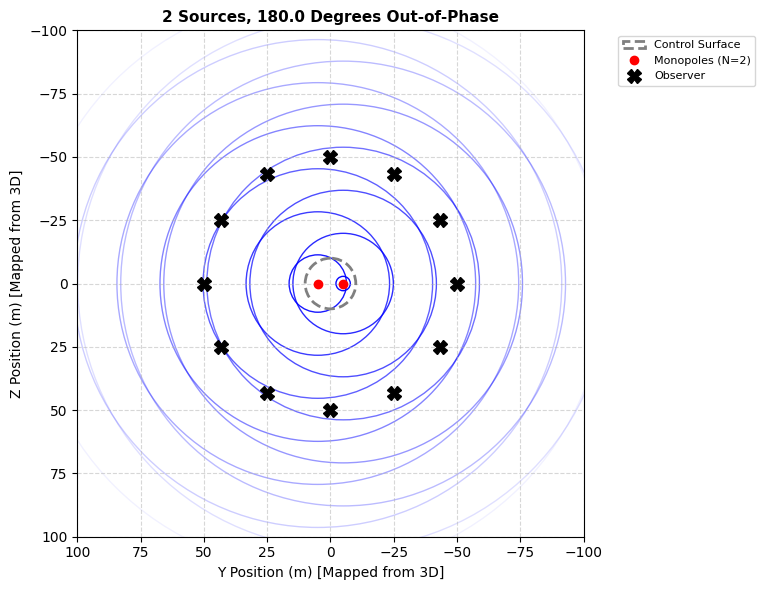

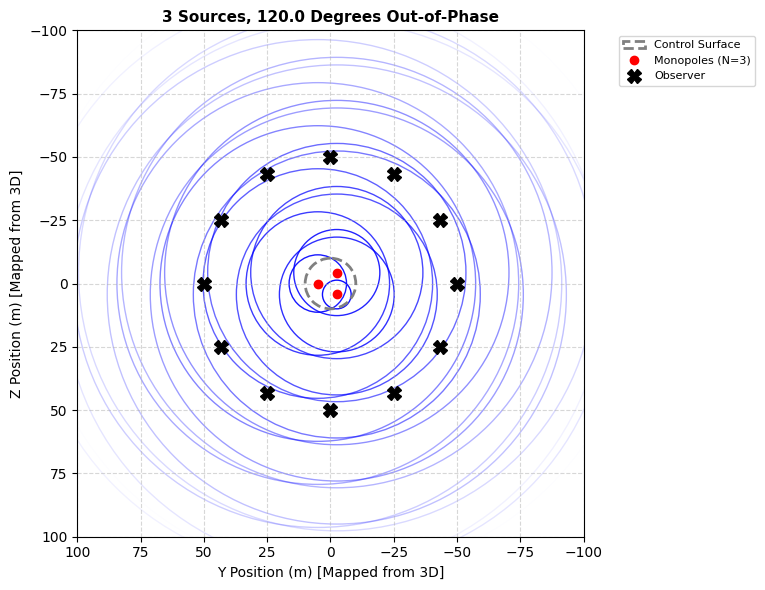

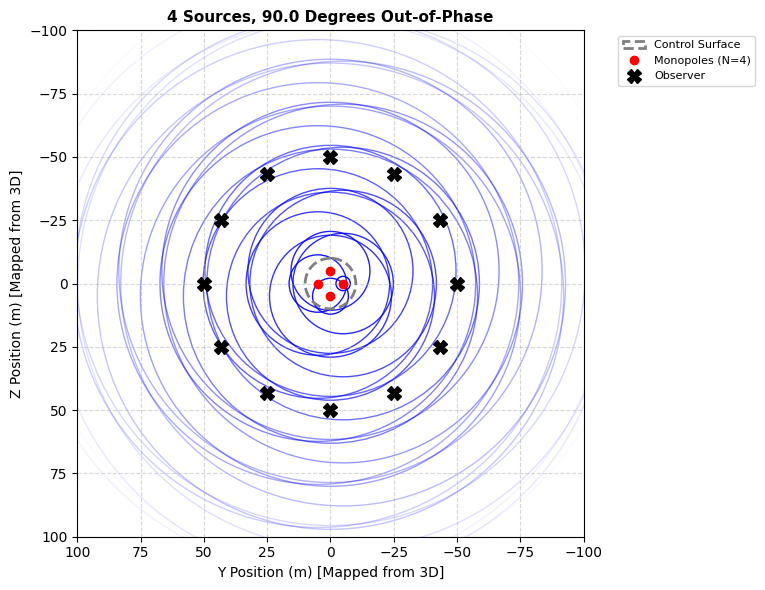

In [21]:
D_obs = 50
obs_1 = [(D_obs, 0.0)]

angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
obs_12 = [(D_obs * np.cos(a), D_obs * np.sin(a)) for a in angles]

for i in range(2, 5, 1):
    sim = RotatingArraySimulator(n_sources=i, delta=5, f_rot=0.0, phase_lag=True, n_blades=1, title=f"{i} Sources, {np.round(np.rad2deg(2*np.pi/i))} Degrees Out-of-Phase",
                                vector_lines=False, cs_radius=10,
                                x_bounds=(100, -100), y_bounds=(100, -100), obs_positions=obs_12)
    sim.generate_gif(f"{i}_outofphase.gif")

Generating 36_dense.gif...
Done!


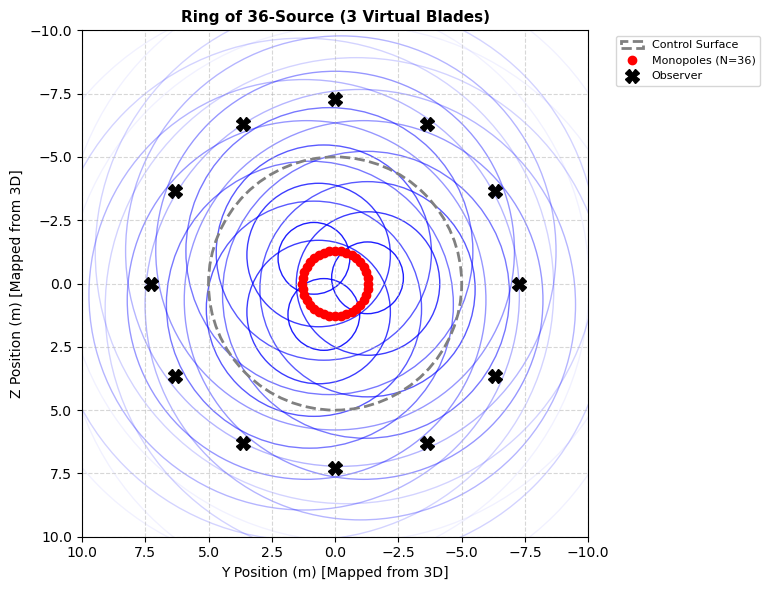

In [6]:
D_obs = 7.28
obs_1 = [(D_obs, 0.0)]

angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
obs_12 = [(D_obs * np.cos(a), D_obs * np.sin(a)) for a in angles]

sim = RotatingArraySimulator(n_sources=36, delta=1.3, f_rot=0.0, phase_lag=True, n_blades=3, title="Ring of 36-Source (3 Virtual Blades)",
                             vector_lines=False, cs_radius=5,
                            x_bounds=(10, -10), y_bounds=(10, -10), obs_positions=obs_12)
sim.generate_gif("36_dense.gif")

In [ ]:
f_rot = 100.0
f_source = f_rot / 4.0  # 25 Hz
duration = 1.0 / f_source  # 0.04s (Captures exactly 1 harmonic envelope / 4 rotations)
fps = 1000  # Required to get 40 frames over a 0.04s physical window
delta = 5.0 # Scaled up slightly from 0.5m so it is visible in the plot

# 2. Observer Arrays
D_obs = 25.0
obs_1 = [(D_obs, 0.0)]

angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
obs_12 = [(D_obs * np.cos(a), D_obs * np.sin(a)) for a in angles]

# 3. Plot Boundaries (Centered for the 12-microphone ring)
bounds = {'x_bounds': (-50, 50), 'y_bounds': (-50, 50)}

sim_test = RotatingArraySimulator(f_source=200, f_rot=100, n_sources=4, delta=delta,
                               obs_positions=obs_12, duration=duration, fps=fps,
                               title=r"1 Source ($f_{rot}=100$ Hz, $f_{source}=200$ Hz)", 
                               **bounds, vector_lines=False)

sim_test.generate_gif("sim_test.gif")

Generating sim_test.gif...
Done!


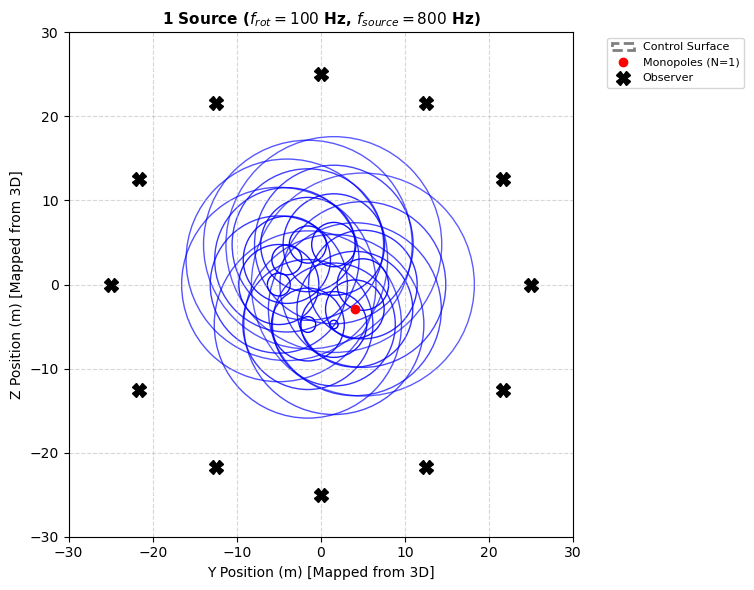

In [7]:
import numpy as np

# 1. Physics Parameters
f_rot = 100.0
f_source = f_rot / 4.0  # 25 Hz
duration = 1.0 / f_source  # 0.04s (Captures exactly 1 harmonic envelope / 4 rotations)
fps = 1000  # Required to get 40 frames over a 0.04s physical window
delta = 5.0 # Scaled up slightly from 0.5m so it is visible in the plot

# 2. Observer Arrays
D_obs = 25.0
obs_1 = [(D_obs, 0.0)]

angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
obs_12 = [(D_obs * np.cos(a), D_obs * np.sin(a)) for a in angles]

# 3. Plot Boundaries (Centered for the 12-microphone ring)
bounds = {'x_bounds': (-30, 30), 'y_bounds': (-30, 30)}

# # --- Case 1: One Source, Single Observer ---
# sim_1 = RotatingArraySimulator(f_source=f_source, f_rot=f_rot, n_sources=1, delta=delta,
#                                obs_positions=obs_1, duration=duration, fps=fps,
#                                title=r"1 Source ($f_{rot}=100$ Hz, $f_{source}=25$ Hz)", 
#                                **bounds, vector_lines=False)
# sim_1.generate_gif("sim_1_source.gif")

# # --- Case 2: Two Sources, 12 Observers ---
# sim_2 = RotatingArraySimulator(f_source=f_source, f_rot=f_rot, n_sources=2, delta=delta,
#                                obs_positions=obs_12, duration=duration, fps=fps,
#                                title=r"2 Sources ($f_{rot}=100$ Hz, $f_{source}=25$ Hz)", 
#                                **bounds, vector_lines=False)
# sim_2.generate_gif("sim_2_sources.gif")

# # --- Case 3: Four Sources, 12 Observers ---
# sim_4 = RotatingArraySimulator(f_source=f_source, f_rot=f_rot, n_sources=4, delta=delta,
#                                obs_positions=obs_12, duration=duration, fps=fps,
#                                title=r"4 Sources ($f_{rot}=100$ Hz, $f_{source}=25$ Hz)", 
#                                **bounds, vector_lines=False)
# sim_4.generate_gif("sim_4_sources.gif")

# # --- Case 4: Eight Sources, 12 Observers ---
# sim_8 = RotatingArraySimulator(f_source=f_source, f_rot=f_rot, n_sources=8, delta=delta,
#                                obs_positions=obs_12, duration=duration, fps=fps,
#                                title=r"8 Sources ($f_{rot}=100$ Hz, $f_{source}=25$ Hz)", 
#                                **bounds, vector_lines=False)
# sim_8.generate_gif("sim_8_sources.gif")

sim_test = RotatingArraySimulator(f_source=800, f_rot=100, n_sources=1, delta=delta,
                               obs_positions=obs_12, duration=duration, fps=fps,
                               title=r"1 Source ($f_{rot}=100$ Hz, $f_{source}=800$ Hz)", 
                               **bounds, vector_lines=False)

sim_test.generate_gif("sim_test.gif")

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.animation as animation
# from matplotlib.patches import Circle

# class AcousticSimulator:
#     def __init__(self, c=340.0, omega=10.0, 
#                  source_type='single', cs_radius=100.0,
#                  src_init_pos=(0.0, 0.0), src_vel=(150.0, 0.0),
#                  obs_init_pos=(1500.0, 500.0), obs_vel=(0.0, 0.0),
#                  duration=3.5, fps=30, vector_lines=True, title=None,
#                  x_bounds = (-200, 1600), y_bounds=(-600,600)):
        
#         # Physics Parameters
#         self.c = c
#         self.omega = omega
#         self.k = self.omega / self.c
#         self.source_type = source_type
        
#         # Dynamic Geometry
#         self.cs_radius = cs_radius
#         self.src_pos = np.array(src_init_pos, dtype=float)
#         self.src_vel = np.array(src_vel, dtype=float)
#         self.obs_pos = np.array(obs_init_pos, dtype=float)
#         self.obs_vel = np.array(obs_vel, dtype=float)
        
#         # Display Toggles
#         self.vector_lines = vector_lines
#         self.title = title
#         self.x_bounds = x_bounds
#         self.y_bounds = y_bounds
        
#         # Animation Settings
#         self.fps = fps
#         self.dt = 1.0 / fps
#         self.frames = int(duration * fps)
#         self.emit_rate = 10  # Waves per second
#         self.frames_per_emission = int(self.fps / self.emit_rate)
        
#         # State tracking
#         self.waves = []
#         self.emission_times = []
#         self.current_time = 0.0

#         # Calculate Dual Source Separation (delta)
#         if self.source_type == 'dual':
#             self.delta = 0.01 / self.k
#             # Multiply separation ONLY for visual clarity on a large plot
#             self.viz_delta = self.delta * 50.0 
#         else:
#             self.delta = 0.0
#             self.viz_delta = 0.0

#         self.setup_plot()

#     def setup_plot(self):
#         """Initializes the Matplotlib figure and drawing objects."""
#         self.fig, self.ax = plt.subplots(figsize=(12, 5))
        
#         # Dynamic framing based on initial positions and velocities
#         max_x = max(self.src_pos[0] + self.src_vel[0]*3, self.obs_pos[0] + self.obs_vel[0]*3) + 200
#         min_x = min(self.src_pos[0], self.obs_pos[0]) - 300
#         self.ax.set_xlim(self.x_bounds)
#         self.ax.set_ylim(self.y_bounds)
#         self.ax.set_aspect('equal')
        
#         title_str = f"{self.title}\n"
#         title_str += f"U_src={self.src_vel} m/s | U_obs={self.obs_vel} m/s | CS_r={self.cs_radius}m"
#         self.ax.set_title(title_str, fontsize=11)
#         self.ax.set_xlabel('X Position (m)')
#         self.ax.set_ylabel('Y Position (m)')
#         self.ax.grid(True, linestyle='--', alpha=0.5)

#         # Plot Elements
#         self.control_surface = Circle((0, 0), radius=self.cs_radius, fill=False, color='grey', ls='--', lw=2, zorder=2, label='Control Surface')
#         self.ax.add_patch(self.control_surface)
        
#         self.src_center_dot, = self.ax.plot([], [], 'ro', markersize=6, zorder=5, label='Point Source')
        
#         if self.source_type == 'dual':
#             self.src1_dot, = self.ax.plot([], [], 'r+', markersize=8, zorder=5, label='+ Monopole')
#             self.src2_dot, = self.ax.plot([], [], 'b_', markersize=8, zorder=5, label='- Monopole')
            
#         self.obs_dot, = self.ax.plot([], [], 'kX', markersize=10, zorder=5, label='Observer')
        
#         # Tracking Lines (Conditionally add labels so they don't show up in legend if turned off)
#         if self.vector_lines:
#             self.analytical_line, = self.ax.plot([], [], 'k-', alpha=0.4, lw=1, zorder=3, label='Analytical Vector (r)')
#             self.numerical_line, = self.ax.plot([], [], 'g-', lw=2, zorder=4, label='Numerical Vector (CS to Obs)')
#         else:
#             self.analytical_line, = self.ax.plot([], [], visible=False)
#             self.numerical_line, = self.ax.plot([], [], visible=False)
            
#         self.ax.legend(loc='upper right', fontsize=8)

#     def init_anim(self):
#         """Initializes empty data for the animation start."""
#         self.src_center_dot.set_data([], [])
#         self.obs_dot.set_data([], [])
#         self.analytical_line.set_data([], [])
#         self.numerical_line.set_data([], [])
#         if self.source_type == 'dual':
#             self.src1_dot.set_data([], [])
#             self.src2_dot.set_data([], [])
#         return self.get_artists()

#     def get_artists(self):
#         """Returns all changing matplotlib objects for blitting."""
#         artists = [self.src_center_dot, self.obs_dot, self.control_surface, 
#                    self.analytical_line, self.numerical_line] + self.waves
#         if self.source_type == 'dual':
#             artists.extend([self.src1_dot, self.src2_dot])
#         return artists

#     def animate(self, frame):
#         """The core physics and update loop for each frame."""
#         self.current_time = frame * self.dt
        
#         # 1. Kinematics updates
#         curr_src_pos = self.src_pos + self.src_vel * self.current_time
#         curr_obs_pos = self.obs_pos + self.obs_vel * self.current_time
        
#         # 2. Geometry updates
#         self.src_center_dot.set_data([curr_src_pos[0]], [curr_src_pos[1]])
#         self.obs_dot.set_data([curr_obs_pos[0]], [curr_obs_pos[1]])
#         self.control_surface.center = (curr_src_pos[0], curr_src_pos[1])
        
#         if self.source_type == 'dual':
#             # Offset sources along X-axis using the visual delta
#             self.src1_dot.set_data([curr_src_pos[0] - self.viz_delta/2], [curr_src_pos[1]])
#             self.src2_dot.set_data([curr_src_pos[0] + self.viz_delta/2], [curr_src_pos[1]])

#         # 3. Radiation Vector Tracking
#         if self.vector_lines:
#             vec_to_obs = curr_obs_pos - curr_src_pos
#             dist_to_obs = np.linalg.norm(vec_to_obs)
            
#             if dist_to_obs > 0:
#                 unit_vec = vec_to_obs / dist_to_obs
#                 cs_intersection = curr_src_pos + unit_vec * self.cs_radius
                
#                 self.analytical_line.set_data([curr_src_pos[0], curr_obs_pos[0]], [curr_src_pos[1], curr_obs_pos[1]])
#                 self.numerical_line.set_data([cs_intersection[0], curr_obs_pos[0]], [cs_intersection[1], curr_obs_pos[1]])
        
#         # 4. Wave Emission & Propagation (with pi Phase Delay)
#         if frame % self.frames_per_emission == 0:
#             if self.source_type == 'single':
#                 self.emit_wave(curr_src_pos, color='blue', ls='solid')
#             elif self.source_type == 'dual':
#                 # Positive monopole emits at t=0
#                 pos1 = curr_src_pos + np.array([-self.viz_delta/2, 0])
#                 self.emit_wave(pos1, color='red', ls='solid')

#         # Negative monopole emits half a cycle later (pi phase shift)
#         if self.source_type == 'dual' and (frame + self.frames_per_emission // 2) % self.frames_per_emission == 0:
#             pos2 = curr_src_pos + np.array([self.viz_delta/2, 0])
#             self.emit_wave(pos2, color='blue', ls='dotted')

#         # Radiate waves
#         for i, wave in enumerate(self.waves):
#             r = self.c * (self.current_time - self.emission_times[i])
#             wave.set_radius(r)
#             alpha = max(0, 1.0 - (r / 1500.0)) 
#             wave.set_alpha(alpha)
            
#         return self.get_artists()

#     def emit_wave(self, position, color, ls):
#         circle = Circle(tuple(position), radius=0, fill=False, color=color, ls=ls, lw=1.2, alpha=1.0, zorder=1)
#         self.ax.add_patch(circle)
#         self.waves.append(circle)
#         self.emission_times.append(self.current_time)

#     def generate_gif(self, filename="fwh_simulation.gif"):
#         """Compiles the animation and saves it to disk."""
#         print(f"Generating {filename}...")
#         anim = animation.FuncAnimation(self.fig, self.animate, init_func=self.init_anim, 
#                                        frames=self.frames, interval=1000/self.fps, blit=True)
#         anim.save(filename, writer='pillow', fps=self.fps)
#         print("Done!")